* Horizonte: predecir la demanda de los próximos 7 días.
* Nivel: una predicción por estación individual.
* Datos de partida: viajes_p1, con los 38,920,173 registros que ya validamos.
* Objetivo del modelo: estimar cuántos viajes comenzarán en cada estación por día.

Hay una distinción importante: para predecir los próximos siete días, construiremos primero una tabla histórica con una fila por estación y fecha. El modelo aprenderá de esa tabla; no entrenaremos directamente con los casi 39 millones de viajes individuales.

In [62]:
#Paso 1. Librerías y configuración del proyecto

import pandas as pd
import numpy as np
import mlflow
from sklearn.metrics import mean_absolute_error, mean_squared_error
import mlflow.sklearn
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer


from equipo52_module.config import PROCESSED_DATA_DIR, VIAJES_FILE

In [63]:
# Paso 2. Cargar el conjunto filtrado de P1

archivo_p1 = PROCESSED_DATA_DIR / "viajes_p1_filtrados.parquet"

viajes_p1 = pd.read_parquet(archivo_p1)

# Asegurar el tipo de dato de la fecha
viajes_p1["Inicio_del_viaje"] = pd.to_datetime(
    viajes_p1["Inicio_del_viaje"]
)

print(f"Registros: {len(viajes_p1):,}")
print(f"Columnas: {viajes_p1.shape[1]}")
print(f"Fecha inicial: {viajes_p1['Inicio_del_viaje'].min()}")
print(f"Fecha final: {viajes_p1['Inicio_del_viaje'].max()}")

SEMILLA_P1 = 42

display(viajes_p1.head())

Registros: 38,920,173
Columnas: 5
Fecha inicial: 2014-12-01 00:33:47
Fecha final: 2026-09-30 23:59:48


,Viaje_Id,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,4601,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47
1,4604,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5
2,4628,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79
3,4631,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79
4,4632,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79


- Agrupamos los viajes por Origen_Id y fecha, eliminando la hora para consolidar cada día.
- Contamos los viajes iniciados en cada estación.
- Ordenamos los resultados por estación y fecha.

Por ejemplo, si una estación registró 120 viajes el lunes, aparecerá una fila con Numero_viajes = 120 para ese día.

In [64]:
# Paso 3. Construir la demanda diaria por estación

demanda_diaria_p1 = (
    viajes_p1.groupby(
        [
            "Origen_Id",
            viajes_p1["Inicio_del_viaje"].dt.normalize()
        ]
    )
    .size()
    .reset_index(name="Numero_viajes")
)

demanda_diaria_p1.columns = [
    "Origen_Id",
    "Fecha",
    "Numero_viajes"
]

demanda_diaria_p1 = demanda_diaria_p1.sort_values(
    ["Origen_Id", "Fecha"]
).reset_index(drop=True)

# Revisar el resultado
display(demanda_diaria_p1.head())

print(f"Registros diarios: {len(demanda_diaria_p1):,}")
print(f"Estaciones: {demanda_diaria_p1['Origen_Id'].nunique():,}")
print(f"Fecha inicial: {demanda_diaria_p1['Fecha'].min()}")
print(f"Fecha final: {demanda_diaria_p1['Fecha'].max()}")

,Origen_Id,Fecha,Numero_viajes
0,2,2014-12-01,2
1,2,2014-12-02,6
2,2,2014-12-03,7
3,2,2014-12-04,11
4,2,2014-12-05,8


Registros diarios: 1,150,251
Estaciones: 472
Fecha inicial: 2014-12-01 00:00:00
Fecha final: 2026-09-30 00:00:00


Observamos que tenemos 1.15 millones de combinaciones estación-fecha, frente a los 38.9 millones de viajes originales. Esto es lo esperado al contar los viajes diarios en lugar de conservar una fila por viaje.

Revisar el historial por estación

In [65]:
# Paso 4. Resumen del historial por estación

historial_estaciones_p1 = (
    demanda_diaria_p1.groupby("Origen_Id")
    .agg(
        Primera_fecha=("Fecha", "min"),
        Ultima_fecha=("Fecha", "max"),
        Dias_con_registros=("Fecha", "nunique"),
        Total_viajes=("Numero_viajes", "sum")
    )
    .reset_index()
)

display(
    historial_estaciones_p1
    .sort_values("Primera_fecha")
    .head(10)
)

print(
    f"Estaciones con historial: "
    f"{historial_estaciones_p1['Origen_Id'].nunique():,}"
)

print(
    f"Promedio de días con registros por estación: "
    f"{historial_estaciones_p1['Dias_con_registros'].mean():,.1f}"
)

,Origen_Id,Primera_fecha,Ultima_fecha,Dias_con_registros,Total_viajes
0,2,2014-12-01,2026-09-30,4321,192386
61,65,2014-12-01,2026-09-30,4318,346689
60,64,2014-12-01,2026-09-30,4322,274565
59,63,2014-12-01,2026-09-30,4321,285161
58,62,2014-12-01,2026-09-30,4286,223574
57,61,2014-12-01,2026-09-30,4316,153086
56,60,2014-12-01,2026-09-30,4314,136680
55,59,2014-12-01,2026-09-30,4309,121360
54,58,2014-12-01,2026-09-30,4247,364977
53,57,2014-12-01,2026-09-30,4298,91059


Estaciones con historial: 472
Promedio de días con registros por estación: 2,437.0


Antes de tratar los días sin registros, verifiquemos que el número de viajes se conserve y que no existan duplicados por estación y fecha.

In [66]:
# Paso 5. Validaciones de la agregación

total_viajes_originales = len(viajes_p1)
total_viajes_agregados = demanda_diaria_p1["Numero_viajes"].sum()

duplicados_estacion_fecha = demanda_diaria_p1.duplicated(
    subset=["Origen_Id", "Fecha"]
).sum()

print(f"Viajes originales: {total_viajes_originales:,}")
print(f"Viajes agregados: {total_viajes_agregados:,}")
print(
    f"Diferencia: "
    f"{total_viajes_originales - total_viajes_agregados:,}"
)
print(f"Duplicados estación-fecha: {duplicados_estacion_fecha:,}")

assert total_viajes_originales == total_viajes_agregados
assert duplicados_estacion_fecha == 0

print("Validaciones superadas.")

Viajes originales: 38,920,173
Viajes agregados: 38,920,173
Diferencia: 0
Duplicados estación-fecha: 0
Validaciones superadas.


Revisar los días faltantes antes de completar el calendario: para cuantificar cuántos días tiene cada estación y comparar sus días observados con los días de calendario entre su primera y última fecha registrada.



In [67]:
# Paso 6. Analizar la cobertura diaria por estación

historial_estaciones_p1["Dias_calendario"] = (
    historial_estaciones_p1["Ultima_fecha"]
    - historial_estaciones_p1["Primera_fecha"]
).dt.days + 1

historial_estaciones_p1["Dias_sin_registro"] = (
    historial_estaciones_p1["Dias_calendario"]
    - historial_estaciones_p1["Dias_con_registros"]
)

historial_estaciones_p1["Cobertura_pct"] = (
    historial_estaciones_p1["Dias_con_registros"]
    / historial_estaciones_p1["Dias_calendario"]
    * 100
)

display(
    historial_estaciones_p1[
        [
            "Origen_Id",
            "Primera_fecha",
            "Ultima_fecha",
            "Dias_con_registros",
            "Dias_calendario",
            "Dias_sin_registro",
            "Cobertura_pct"
        ]
    ]
    .sort_values("Cobertura_pct")
    .head(10)
)

print(
    f"Promedio de cobertura por estación: "
    f"{historial_estaciones_p1['Cobertura_pct'].mean():.2f}%"
)
print(
    f"Mediana de cobertura por estación: "
    f"{historial_estaciones_p1['Cobertura_pct'].median():.2f}%"
)
print(
    f"Estaciones con cobertura menor al 90%: "
    f"{(historial_estaciones_p1['Cobertura_pct'] < 90).sum():,}"
)

,Origen_Id,Primera_fecha,Ultima_fecha,Dias_con_registros,Dias_calendario,Dias_sin_registro,Cobertura_pct
109,124,2016-04-08,2020-11-17,22,1685,1663,1.305638
88,94,2015-05-08,2026-09-30,1933,4164,2231,46.421710
96,104,2015-05-08,2026-09-30,2862,4164,1302,68.731988
428,465,2026-06-26,2026-09-28,73,95,22,76.842105
99,107,2015-05-08,2026-09-30,3382,4164,782,81.219981
451,497,2026-07-02,2026-09-30,75,91,16,82.417582
104,115,2015-05-07,2026-09-30,3433,4165,732,82.424970
162,180,2016-08-18,2026-09-30,3106,3696,590,84.036797
106,118,2015-05-07,2026-09-30,3534,4165,631,84.849940
81,85,2014-12-01,2026-09-30,3757,4322,565,86.927348


Promedio de cobertura por estación: 98.30%
Mediana de cobertura por estación: 99.79%
Estaciones con cobertura menor al 90%: 17


Identificar los días faltantes por estación: Antes de completar el calendario, revisemos las estaciones con cobertura inferior al 90%

In [68]:
# Paso 7. Revisar estaciones con menor cobertura

estaciones_baja_cobertura = (
    historial_estaciones_p1
    .loc[
        historial_estaciones_p1["Cobertura_pct"] < 90,
        [
            "Origen_Id",
            "Primera_fecha",
            "Ultima_fecha",
            "Dias_con_registros",
            "Dias_calendario",
            "Dias_sin_registro",
            "Cobertura_pct"
        ]
    ]
    .sort_values("Cobertura_pct")
)

display(estaciones_baja_cobertura)

,Origen_Id,Primera_fecha,Ultima_fecha,Dias_con_registros,Dias_calendario,Dias_sin_registro,Cobertura_pct
109,124,2016-04-08,2020-11-17,22,1685,1663,1.305638
88,94,2015-05-08,2026-09-30,1933,4164,2231,46.421710
96,104,2015-05-08,2026-09-30,2862,4164,1302,68.731988
428,465,2026-06-26,2026-09-28,73,95,22,76.842105
99,107,2015-05-08,2026-09-30,3382,4164,782,81.219981
451,497,2026-07-02,2026-09-30,75,91,16,82.417582
104,115,2015-05-07,2026-09-30,3433,4165,732,82.424970
162,180,2016-08-18,2026-09-30,3106,3696,590,84.036797
106,118,2015-05-07,2026-09-30,3534,4165,631,84.849940
81,85,2014-12-01,2026-09-30,3757,4322,565,86.927348


Revisar los periodos sin registros: para examinar las 17 estaciones y calcular cuál es su mayor intervalo consecutivo sin viajes registrados. Esto nos ayudará a distinguir huecos aislados de periodos largos de inactividad.

In [69]:
# Paso 8. Identificar intervalos consecutivos sin registros

estaciones_revision = estaciones_baja_cobertura["Origen_Id"].tolist()
intervalos_sin_registro = []

for estacion in estaciones_revision:
    fechas_observadas = pd.DatetimeIndex(
        demanda_diaria_p1.loc[
            demanda_diaria_p1["Origen_Id"] == estacion, "Fecha"
        ].sort_values().unique()
    )

    if len(fechas_observadas) == 0:
        continue

    calendario = pd.date_range(
        start=fechas_observadas.min(),
        end=fechas_observadas.max(),
        freq="D"
    )

    fechas_faltantes = calendario.difference(fechas_observadas)

    if len(fechas_faltantes) == 0:
        continue

    # Separar los días faltantes en intervalos consecutivos
    grupos = (
        pd.Series(fechas_faltantes)
        .diff()
        .dt.days
        .ne(1)
        .cumsum()
    )

    huecos = (
        pd.DataFrame({
            "Fecha": fechas_faltantes,
            "Grupo": grupos.to_numpy()
        })
        .groupby("Grupo")["Fecha"]
        .agg(Inicio="min", Fin="max", Dias="size")
    )

    mayor_hueco = huecos.sort_values("Dias").iloc[-1]

    intervalos_sin_registro.append({
        "Origen_Id": estacion,
        "Dias_faltantes": len(fechas_faltantes),
        "Mayor_hueco_dias": int(mayor_hueco["Dias"]),
        "Inicio_mayor_hueco": mayor_hueco["Inicio"],
        "Fin_mayor_hueco": mayor_hueco["Fin"]
    })

resumen_huecos_p1 = pd.DataFrame(intervalos_sin_registro)

display(
    resumen_huecos_p1
    .sort_values("Mayor_hueco_dias", ascending=False)
)

,Origen_Id,Dias_faltantes,Mayor_hueco_dias,Inicio_mayor_hueco,Fin_mayor_hueco
1,94,2231,1778,2016-10-07,2021-08-19
2,104,1302,788,2024-06-07,2026-08-03
7,180,590,590,2025-01-29,2026-09-10
9,85,565,554,2015-04-01,2016-10-05
0,124,1663,480,2017-09-28,2019-01-20
14,91,456,33,2015-09-04,2015-10-06
6,115,732,24,2015-12-18,2016-01-10
10,95,531,23,2016-05-28,2016-06-19
15,356,112,21,2024-11-07,2024-11-27
4,107,782,19,2015-12-19,2016-01-06


Para definir el criterio para construir la tabla diaria:

1. Se conservarán los conteos observados tal como están.
2. No se incluirán días anteriores a la primera fecha ni posteriores a la última fecha registrada de cada estación.
3. No se rellenarán automáticamente los huecos internos con cero, porque no sabemos si representan ausencia real de demanda o falta de datos.
4. No tenemos una fuente que confirme la operación de cada estación, no podemos afirmar que los días sin registros sean días sin viajes.

Para construir un primer modelo, podemos trabajar inicialmente con los días observados. Esto evita inventar valores, aunque implica que la evaluación no representará los días sin registros.

Crearemos una copia de trabajo con las columnas necesarias y agregaremos variables de calendario.

In [70]:
# Paso 9A. Preparar la tabla de trabajo para P1
demanda_modelo_p1 = demanda_diaria_p1.copy()
demanda_modelo_p1["Dia_semana"] = (
    demanda_modelo_p1["Fecha"].dt.dayofweek
)

demanda_modelo_p1["Mes"] = (
    demanda_modelo_p1["Fecha"].dt.month
)

demanda_modelo_p1["Año"] = (
    demanda_modelo_p1["Fecha"].dt.year
)

demanda_modelo_p1["Dia_mes"] = (
    demanda_modelo_p1["Fecha"].dt.day
)

demanda_modelo_p1["Fin_de_semana"] = (
    demanda_modelo_p1["Dia_semana"] >= 5
).astype(int)

display(demanda_modelo_p1.head())

print(f"Registros: {len(demanda_modelo_p1):,}")
print(
    f"Estaciones: "
    f"{demanda_modelo_p1['Origen_Id'].nunique():,}"
)
print(
    f"Fechas únicas: "
    f"{demanda_modelo_p1['Fecha'].nunique():,}"
)

,Origen_Id,Fecha,Numero_viajes,Dia_semana,Mes,Año,Dia_mes,Fin_de_semana
0,2,2014-12-01,2,0,12,2014,1,0
1,2,2014-12-02,6,1,12,2014,2,0
2,2,2014-12-03,7,2,12,2014,3,0
3,2,2014-12-04,11,3,12,2014,4,0
4,2,2014-12-05,8,4,12,2014,5,0


Registros: 1,150,251
Estaciones: 472
Fechas únicas: 4,322


* Dia_semana: lunes = 0 y domingo = 6.
* Mes: mes del año, del 1 al 12.
* Año: año de la observación.
* Dia_mes: día del mes.
* Fin_de_semana: 1 para sábado y domingo; 0 para lunes a viernes.

Revisar la distribución de la demanda diaria: se revisará la distribución de Numero_viajes para entender la escala de la variable objetivo y detectar valores que requieran atención.

In [71]:
# Paso 10. Resumen estadístico de la demanda diaria

display(
    demanda_modelo_p1["Numero_viajes"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame()
)

print(
    "Días con más de 100 viajes:",
    (demanda_modelo_p1["Numero_viajes"] > 100).sum()
)

print(
    "Demanda diaria máxima:",
    demanda_modelo_p1["Numero_viajes"].max()
)

,Numero_viajes
count,1.150251e+06
mean,3.383624e+01
std,3.426837e+01
min,1.000000e+00
1%,1.000000e+00
5%,3.000000e+00
25%,1.100000e+01
50%,2.400000e+01
75%,4.500000e+01
95%,9.500000e+01


Días con más de 100 viajes: 49479
Demanda diaria máxima: 561


Crear variables históricas de demanda: para incorporar la demanda registrada en días anteriores para que el modelo pueda aprender patrones temporales. Usaremos tres variables iniciales:
- Viajes_dia_anterior: demanda del día anterior.
- Viajes_misma_semana_anterior: demanda de hace 7 días.
- Promedio_7_dias_previos: promedio de los siete días anteriores.

In [72]:
# Paso 11. Crear una serie diaria por estación
# Los días sin registros quedan como NaN; no se interpretan como cero.

series_diarias_p1 = []

for estacion, grupo in demanda_modelo_p1.groupby("Origen_Id"):
    grupo = grupo.sort_values("Fecha").set_index("Fecha")

    calendario = pd.date_range(
        start=grupo.index.min(),
        end=grupo.index.max(),
        freq="D"
    )

    grupo_diario = grupo.reindex(calendario)
    grupo_diario.index.name = "Fecha"
    grupo_diario["Origen_Id"] = estacion

    series_diarias_p1.append(grupo_diario)

demanda_diaria_completa_p1 = (
    pd.concat(series_diarias_p1)
    .reset_index()
    .sort_values(["Origen_Id", "Fecha"])
    .reset_index(drop=True)
)

print(
    f"Registros después de completar calendarios: "
    f"{len(demanda_diaria_completa_p1):,}"
)

print(
    f"Días sin registro conservados como faltantes: "
    f"{demanda_diaria_completa_p1['Numero_viajes'].isna().sum():,}"
)

display(demanda_diaria_completa_p1.head())

Registros después de completar calendarios: 1,170,152
Días sin registro conservados como faltantes: 19,901


,Fecha,Origen_Id,Numero_viajes,Dia_semana,Mes,Año,Dia_mes,Fin_de_semana
0,2014-12-01,2,2.0,0.0,12.0,2014.0,1.0,0.0
1,2014-12-02,2,6.0,1.0,12.0,2014.0,2.0,0.0
2,2014-12-03,2,7.0,2.0,12.0,2014.0,3.0,0.0
3,2014-12-04,2,11.0,3.0,12.0,2014.0,4.0,0.0
4,2014-12-05,2,8.0,4.0,12.0,2014.0,5.0,0.0


- Registros antes de completar calendarios: 1,150,251.
- Registros después de completar calendarios: 1,170,152.
- Días sin registro conservados como NaN: 19,901.
Esto representa aproximadamente 1.7 % de los registros diarios que ahora están identificados como faltantes. Es importante conservarlos así por el momento, porque no sabemos si corresponden a días sin viajes o a interrupciones en los datos.

Recalcular las variables de calendario: Al insertar fechas nuevas, las variables Dia_semana, Mes, Anio, Dia_mes y Fin_de_semana quedaron como NaN en esas filas. Vamos a recalcularlas usando la columna Fecha.

In [73]:
# Paso 12. Recalcular variables de calendario

demanda_diaria_completa_p1["Dia_semana"] = (
    demanda_diaria_completa_p1["Fecha"].dt.dayofweek
)

demanda_diaria_completa_p1["Mes"] = (
    demanda_diaria_completa_p1["Fecha"].dt.month
)

demanda_diaria_completa_p1["Anio"] = (
    demanda_diaria_completa_p1["Fecha"].dt.year
)

demanda_diaria_completa_p1["Dia_mes"] = (
    demanda_diaria_completa_p1["Fecha"].dt.day
)

demanda_diaria_completa_p1["Fin_de_semana"] = (
    demanda_diaria_completa_p1["Dia_semana"] >= 5
).astype(int)

# Validar que las variables de calendario no tengan faltantes
display(
    demanda_diaria_completa_p1[
        [
            "Origen_Id",
            "Fecha",
            "Numero_viajes",
            "Dia_semana",
            "Mes",
            "Anio",
            "Dia_mes",
            "Fin_de_semana"
        ]
    ].head()
)

print(
    "Valores faltantes en Numero_viajes:",
    demanda_diaria_completa_p1["Numero_viajes"].isna().sum()
)

print(
    "Valores faltantes en variables de calendario:",
    demanda_diaria_completa_p1[
        ["Dia_semana", "Mes", "Anio", "Dia_mes", "Fin_de_semana"]
    ].isna().sum().sum()
)

,Origen_Id,Fecha,Numero_viajes,Dia_semana,Mes,Anio,Dia_mes,Fin_de_semana
0,2,2014-12-01,2.0,0,12,2014,1,0
1,2,2014-12-02,6.0,1,12,2014,2,0
2,2,2014-12-03,7.0,2,12,2014,3,0
3,2,2014-12-04,11.0,3,12,2014,4,0
4,2,2014-12-05,8.0,4,12,2014,5,0


Valores faltantes en Numero_viajes: 19901
Valores faltantes en variables de calendario: 0


Crear variables de demanda histórica: para pronosticar cuántos viajes iniciarán en cada estación, utilizaremos la demanda de días anteriores. Crearemos tres variables:

- Viajes_dia_anterior: viajes del día anterior.
- Viajes_hace_7_dias: viajes del mismo día de la semana anterior.
- Promedio_7_dias: promedio de viajes de los siete días anteriores, sin incluir el día que queremos predecir.

In [74]:
# Paso 13. Crear variables de demanda histórica

demanda_diaria_completa_p1 = demanda_diaria_completa_p1.sort_values(
    ["Origen_Id", "Fecha"]
).reset_index(drop=True)

grupos_demanda_p1 = demanda_diaria_completa_p1.groupby(
    "Origen_Id"
)["Numero_viajes"]

# Demanda del día anterior
demanda_diaria_completa_p1["Viajes_dia_anterior"] = (
    grupos_demanda_p1.shift(1)
)

# Demanda del mismo día de la semana anterior
demanda_diaria_completa_p1["Viajes_hace_7_dias"] = (
    grupos_demanda_p1.shift(7)
)

# Promedio de los siete días anteriores, excluyendo el día actual
demanda_diaria_completa_p1["Promedio_7_dias"] = (
    grupos_demanda_p1.transform(
        lambda serie: serie.shift(1).rolling(
            window=7,
            min_periods=7
        ).mean()
    )
)

# Revisar resultados
display(
    demanda_diaria_completa_p1[
        [
            "Origen_Id",
            "Fecha",
            "Numero_viajes",
            "Viajes_dia_anterior",
            "Viajes_hace_7_dias",
            "Promedio_7_dias"
        ]
    ].head(15)
)

# Contar faltantes en las nuevas variables
display(
    demanda_diaria_completa_p1[
        [
            "Viajes_dia_anterior",
            "Viajes_hace_7_dias",
            "Promedio_7_dias"
        ]
    ].isna().sum().to_frame("Valores_faltantes")
)

,Origen_Id,Fecha,Numero_viajes,Viajes_dia_anterior,Viajes_hace_7_dias,Promedio_7_dias
0,2,2014-12-01,2.0,NaN,NaN,NaN
1,2,2014-12-02,6.0,2.0,NaN,NaN
2,2,2014-12-03,7.0,6.0,NaN,NaN
3,2,2014-12-04,11.0,7.0,NaN,NaN
4,2,2014-12-05,8.0,11.0,NaN,NaN
5,2,2014-12-06,9.0,8.0,NaN,NaN
6,2,2014-12-07,5.0,9.0,NaN,NaN
7,2,2014-12-08,7.0,5.0,2.0,6.857143
8,2,2014-12-09,7.0,7.0,6.0,7.571429
9,2,2014-12-10,13.0,7.0,7.0,7.714286


,Valores_faltantes
Viajes_dia_anterior,20373
Viajes_hace_7_dias,23192
Promedio_7_dias,55795


Revisar cuántos registros podemos utilizar: Primero vamos a cuantificar cuántos registros tienen demanda observada y las tres variables históricas disponibles.

In [75]:
# Paso 14. Evaluar disponibilidad de datos para el modelo

columnas_modelo_p1 = [
    "Numero_viajes",
    "Viajes_dia_anterior",
    "Viajes_hace_7_dias",
    "Promedio_7_dias"
]

registros_validos_p1 = demanda_diaria_completa_p1[
    columnas_modelo_p1
].notna().all(axis=1)

print(
    f"Total de registros: "
    f"{len(demanda_diaria_completa_p1):,}"
)

print(
    f"Registros con todas las variables disponibles: "
    f"{registros_validos_p1.sum():,}"
)

print(
    f"Registros que no cumplen todos los requisitos: "
    f"{(~registros_validos_p1).sum():,}"
)

print(
    f"Porcentaje utilizable: "
    f"{registros_validos_p1.mean() * 100:.2f}%"
)

Total de registros: 1,170,152
Registros con todas las variables disponibles: 1,110,780
Registros que no cumplen todos los requisitos: 59,372
Porcentaje utilizable: 94.93%


Definir el periodo de entrenamiento y prueba: Como el objetivo es pronosticar los próximos siete días, no debemos dividir los datos aleatoriamente. Entrenaremos con fechas anteriores y reservaremos el periodo más reciente para la prueba.

Primero revisemos cuántos registros válidos tenemos por año. Esto nos ayudará a elegir un corte temporal que tenga suficientes datos para entrenar y evaluar.

In [76]:
# Paso 15. Revisar disponibilidad de registros válidos por año

resumen_anual_p1 = (
    demanda_diaria_completa_p1.loc[registros_validos_p1]
    .groupby("Anio")
    .agg(
        Registros_validos=("Numero_viajes", "size"),
        Estaciones=("Origen_Id", "nunique"),
        Fecha_inicial=("Fecha", "min"),
        Fecha_final=("Fecha", "max")
    )
    .reset_index()
)

display(resumen_anual_p1)

,Anio,Registros_validos,Estaciones,Fecha_inicial,Fecha_final
0,2014,1698,85,2014-12-08,2014-12-31
1,2015,29759,105,2015-01-01,2015-12-31
2,2016,45124,224,2016-01-01,2016-12-31
3,2017,76814,228,2017-01-01,2017-12-31
4,2018,81797,271,2018-01-01,2018-12-31
5,2019,97330,272,2019-01-01,2019-12-31
6,2020,94931,273,2020-01-01,2020-12-31
7,2021,101864,298,2021-01-01,2021-12-31
8,2022,106629,298,2022-01-01,2022-12-31
9,2023,109537,357,2023-01-01,2023-12-31


Separar entrenamiento y prueba cronológicamente: Por ahora, usaremos únicamente registros que tengan la variable objetivo y las tres variables históricas completas.

In [77]:
# Paso 16. Preparar datos válidos y separar por fecha

datos_modelo_p1 = demanda_diaria_completa_p1.loc[
    registros_validos_p1
].copy()

fecha_inicio_prueba_p1 = pd.Timestamp("2026-07-01")

datos_entrenamiento_p1 = datos_modelo_p1[
    datos_modelo_p1["Fecha"] < fecha_inicio_prueba_p1
].copy()

datos_prueba_p1 = datos_modelo_p1[
    datos_modelo_p1["Fecha"] >= fecha_inicio_prueba_p1
].copy()

print(
    f"Entrenamiento: {len(datos_entrenamiento_p1):,} registros"
)
print(
    f"Prueba: {len(datos_prueba_p1):,} registros"
)

print(
    "Última fecha de entrenamiento:",
    datos_entrenamiento_p1["Fecha"].max()
)
print(
    "Primera fecha de prueba:",
    datos_prueba_p1["Fecha"].min()
)
print(
    "Última fecha de prueba:",
    datos_prueba_p1["Fecha"].max()
)

print(
    "Estaciones en entrenamiento:",
    datos_entrenamiento_p1["Origen_Id"].nunique()
)
print(
    "Estaciones en prueba:",
    datos_prueba_p1["Origen_Id"].nunique()
)

Entrenamiento: 1,070,809 registros
Prueba: 39,971 registros
Última fecha de entrenamiento: 2026-06-30 00:00:00
Primera fecha de prueba: 2026-07-01 00:00:00
Última fecha de prueba: 2026-09-30 00:00:00
Estaciones en entrenamiento: 411
Estaciones en prueba: 470


Crear un modelo base (baseline): Antes de probar modelos más complejos, vamos a establecer una referencia sencilla: predecir que mañana habrá el mismo número de viajes que el día anterior. Es un baseline para una serie temporal y nos ayudará a determinar si un modelo posterior realmente aporta valor.

In [78]:
# Paso 17. Baseline: repetir la demanda del día anterior

datos_prueba_baseline_p1 = datos_prueba_p1.dropna(
    subset=["Numero_viajes", "Viajes_dia_anterior"]
).copy()

datos_prueba_baseline_p1["Prediccion_baseline"] = (
    datos_prueba_baseline_p1["Viajes_dia_anterior"]
)

print(
    "Registros evaluados:",
    len(datos_prueba_baseline_p1)
)

print(
    "Estaciones evaluadas:",
    datos_prueba_baseline_p1["Origen_Id"].nunique()
)

Registros evaluados: 39971
Estaciones evaluadas: 470


Registrar el baseline en MLflow

In [79]:
# Conexión con el servidor local de MLflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Crear o seleccionar el experimento de la pregunta P1
mlflow.set_experiment("MiBici-equipo52")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", "MiBici-P1-Pronostico-Demanda")

Tracking URI: http://127.0.0.1:5000
Experimento: MiBici-P1-Pronostico-Demanda


Calcular métricas del baseline y registrar el experimento

In [80]:
# Calcular métricas del baseline
y_real_p1 = datos_prueba_baseline_p1["Numero_viajes"]
y_pred_baseline_p1 = datos_prueba_baseline_p1["Prediccion_baseline"]

mae_baseline_p1 = mean_absolute_error(
    y_real_p1,
    y_pred_baseline_p1
)

rmse_baseline_p1 = np.sqrt(
    mean_squared_error(y_real_p1, y_pred_baseline_p1)
)

# Registrar el experimento
with mlflow.start_run(run_name="Baseline_P1"):

    # Parámetros del experimento
    
    mlflow.log_param("modelo", "Baseline")
    
    mlflow.log_param("horizonte_dias", 1)
    mlflow.log_param("fecha_inicio_prueba", "2026-07-01")
    mlflow.log_param("fecha_fin_prueba", "2026-09-30")
    mlflow.log_param("registros_entrenamiento", len(datos_entrenamiento_p1))
    mlflow.log_param("registros_prueba", len(datos_prueba_baseline_p1))
    
    # Métricas
    mlflow.log_metric("MAE", mae_baseline_p1)
    mlflow.log_metric("RMSE", rmse_baseline_p1)

    # Etiquetas para identificar el propósito del run
    mlflow.set_tag("tipo_experimento", "baseline")
    mlflow.set_tag("pregunta_proyecto", "P1")
    mlflow.set_tag(
        "limitacion",
        "Evaluacion de un dia adelante; aun no es el pronostico a siete dias"
    )
    mlflow.set_tag("git_commit", "888bc9d")

    print(f"MAE registrado: {mae_baseline_p1:.3f}")
    print(f"RMSE registrado: {rmse_baseline_p1:.3f}")
    print("Experimento registrado en MLflow.")

MAE registrado: 9.229
RMSE registrado: 16.012
Experimento registrado en MLflow.
🏃 View run Baseline_P1 at: http://127.0.0.1:5000/#/experiments/2/runs/9e60a04fb5ee4ce9a7d0d8fcdda67f0e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


Nota: el parámetro horizonte_dias está en 1 porque este baseline predice un día adelante. No debemos etiquetarlo como un pronóstico de siete días hasta implementar y evaluar ese horizonte específicamente.

Preparar el modelo de comparación: Construcción de un modelo de regresión

In [81]:
# Paso 20. Definir variables de entrada y objetivo

variables_p1 = [
    "Viajes_dia_anterior",
    "Viajes_hace_7_dias",
    "Promedio_7_dias",
    "Dia_semana",
    "Mes",
    "Fin_de_semana"
]

objetivo_p1 = "Numero_viajes"

# Preparar conjuntos de entrenamiento y prueba
datos_entrenamiento_modelo_p1 = datos_entrenamiento_p1.dropna(
    subset=variables_p1 + [objetivo_p1]
).copy()

datos_prueba_modelo_p1 = datos_prueba_p1.dropna(
    subset=variables_p1 + [objetivo_p1]
).copy()

X_train_p1 = datos_entrenamiento_modelo_p1[variables_p1]
y_train_p1 = datos_entrenamiento_modelo_p1[objetivo_p1]

X_test_p1 = datos_prueba_modelo_p1[variables_p1]
y_test_p1 = datos_prueba_modelo_p1[objetivo_p1]

print("Registros de entrenamiento:", len(X_train_p1))
print("Registros de prueba:", len(X_test_p1))
print("Variables predictoras:", len(variables_p1))
print("Faltantes en X_train:", X_train_p1.isna().sum().sum())
print("Faltantes en X_test:", X_test_p1.isna().sum().sum())

Registros de entrenamiento: 1070809
Registros de prueba: 39971
Variables predictoras: 6
Faltantes en X_train: 0
Faltantes en X_test: 0


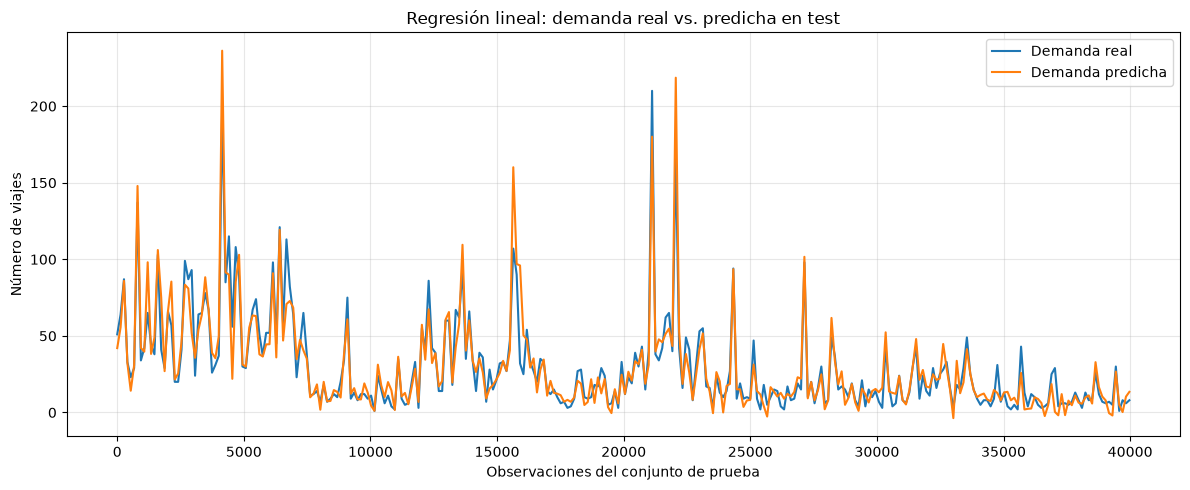

🏃 View run Pipeline_Regresion_Lineal_P1 at: http://127.0.0.1:5000/#/experiments/2/runs/eb47ed7cb9f34fe4a5a450674bc131b8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
MAE pipeline: 6.672
RMSE pipeline: 11.408
Gráfica guardada en: graficas_p1\regresion_lineal_real_vs_predicho.png
Modelo, métricas y gráfica registrados en una corrida nueva de MLflow.


In [82]:
# Paso 21. Entrenar pipeline de regresión lineal

# Crear pipeline
pipeline_regresion_p1 = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

# Entrenar exclusivamente con los datos de entrenamiento
pipeline_regresion_p1.fit(X_train_p1, y_train_p1)

# Predecir sobre el conjunto de prueba
y_pred_regresion_p1 = pipeline_regresion_p1.predict(X_test_p1)

# Calcular métricas
mae_regresion_p1 = mean_absolute_error(
    y_test_p1,
    y_pred_regresion_p1
)

rmse_regresion_p1 = np.sqrt(
    mean_squared_error(y_test_p1, y_pred_regresion_p1)
)

# Preparar datos para la gráfica
y_real_grafica_p1 = np.asarray(y_test_p1).reshape(-1)
y_pred_grafica_p1 = np.asarray(y_pred_regresion_p1).reshape(-1)

# Mostrar hasta 300 observaciones distribuidas en el conjunto de test
n_grafica_p1 = len(y_real_grafica_p1)

indices_grafica_p1 = np.unique(
    np.linspace(
        0,
        n_grafica_p1 - 1,
        min(300, n_grafica_p1),
        dtype=int
    )
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    indices_grafica_p1,
    y_real_grafica_p1[indices_grafica_p1],
    label="Demanda real",
    linewidth=1.5
)

ax.plot(
    indices_grafica_p1,
    y_pred_grafica_p1[indices_grafica_p1],
    label="Demanda predicha",
    linewidth=1.5
)

ax.set_title("Regresión lineal: demanda real vs. predicha en test")
ax.set_xlabel("Observaciones del conjunto de prueba")
ax.set_ylabel("Número de viajes")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

# Guardar gráfica como PNG
carpeta_graficas_p1 = Path("graficas_p1")
carpeta_graficas_p1.mkdir(parents=True, exist_ok=True)

ruta_grafica_regresion_p1 = (
    carpeta_graficas_p1 / "regresion_lineal_real_vs_predicho.png"
)

fig.savefig(
    ruta_grafica_regresion_p1,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Crear una corrida en MLflow
with mlflow.start_run(run_name="Pipeline_Regresion_Lineal_P1"):

    mlflow.log_param("modelo", "LinearRegression")
    mlflow.log_param("preprocesamiento", "StandardScaler")
    mlflow.log_param("registros_entrenamiento", len(X_train_p1))
    mlflow.log_param("registros_prueba", len(X_test_p1))
    mlflow.log_param("fecha_inicio_prueba", "2026-07-01")
    mlflow.log_param("fecha_fin_prueba", "2026-09-30")
    mlflow.log_param("horizonte_dias", 1)

    mlflow.log_metric("MAE", mae_regresion_p1)
    mlflow.log_metric("RMSE", rmse_regresion_p1)

    mlflow.set_tag("tipo_experimento", "pipeline")
    mlflow.set_tag("git_commit", "888bc9d")
    

    # Registrar modelo
    mlflow.sklearn.log_model(
        pipeline_regresion_p1,
        #artifact_path="pipeline_regresion_lineal"
    )

    # Registrar gráfica como artefacto
    mlflow.log_artifact(
        ruta_grafica_regresion_p1
    )

    
print(f"MAE pipeline: {mae_regresion_p1:.3f}")
print(f"RMSE pipeline: {rmse_regresion_p1:.3f}")
print(f"Gráfica guardada en: {ruta_grafica_regresion_p1}")
print("Modelo, métricas y gráfica registrados en una corrida nueva de MLflow.")


La regresión lineal reduce el error absoluto medio en aproximadamente 27.7 % y el RMSE en 28.7 % frente al baseline. Esto indica que las variables históricas y de calendario aportan información útil para predecir la demanda.

Sin embargo, ambos resultados corresponden a predicciones de un día adelante, no al horizonte de siete días que definimos para la pregunta P1. Además, al comparar modelos, debemos mantener exactamente el mismo periodo y los mismos registros de prueba.

Revisar la importancia de las variables: Antes de probar un modelo más complejo, vamos a examinar los coeficientes de la regresión lineal. Como el pipeline usa StandardScaler, los coeficientes permiten comparar la asociación de cada variable con la predicción en la escala estandarizada. No representan causalidad.

In [83]:
# Paso 23. Revisar coeficientes de la regresión lineal
coeficientes_p1 = pd.DataFrame({
    "Variable": variables_p1,
    "Coeficiente": (
        pipeline_regresion_p1
        .named_steps["regresion"]
        .coef_
    )
})

coeficientes_p1["Magnitud_absoluta"] = (
    coeficientes_p1["Coeficiente"].abs()
)

coeficientes_p1 = coeficientes_p1.sort_values(
    "Magnitud_absoluta",
    ascending=False
).reset_index(drop=True)

display(coeficientes_p1)

,Variable,Coeficiente,Magnitud_absoluta
0,Viajes_hace_7_dias,15.743714,15.743714
1,Promedio_7_dias,10.059683,10.059683
2,Viajes_dia_anterior,7.338937,7.338937
3,Fin_de_semana,-2.174809,2.174809
4,Dia_semana,-1.531327,1.531327
5,Mes,-0.610384,0.610384


como las variables se estandarizaron con StandardScaler, los coeficientes corresponden a cambios de una desviación estándar en cada predictor, manteniendo los demás constantes. No son directamente cantidades de viajes por cada unidad original. Además, Dia_semana y Mes son variables cíclicas, por lo que tratarlas como números lineales tiene limitaciones.

Lo más interesante es que Viajes_hace_7_dias tiene el coeficiente de mayor magnitud. Esto es coherente con la posibilidad de que exista un patrón semanal en la demanda de MiBici, aunque el coeficiente por sí solo no demuestra que el patrón sea estable.

Vamos a mejorar el modelo actual incorporando Origen_Id, para que la regresión pueda distinguir las diferencias de demanda habituales entre estaciones. Conservaremos las variables históricas, el corte temporal y el registro de experimentos en MLflow.

La estación es una variable categórica: no debemos tratar, por ejemplo, la estación 100 como el doble de la estación 50. Por eso utilizaremos OneHotEncoder para representarla correctamente dentro del pipeline.

Crear un pipeline que incluya la estación:
Usaremos ColumnTransformer para aplicar el tratamiento correspondiente a cada tipo de variable: codificación para la estación y escalado para las variables numéricas. La transformación se ajustará únicamente con los datos de entrenamiento.

In [84]:
# Paso 24. Preparar pipeline con identificador de estación

# Variables numéricas
variables_numericas_p1 = [
    "Viajes_dia_anterior",
    "Viajes_hace_7_dias",
    "Promedio_7_dias",
    "Dia_semana",
    "Mes",
    "Fin_de_semana"
]

# Variable categórica
variable_categorica_p1 = ["Origen_Id"]

# Preparar los datos con el identificador de estación
X_train_estacion_p1 = datos_entrenamiento_modelo_p1[
    variables_numericas_p1 + variable_categorica_p1
].copy()

X_test_estacion_p1 = datos_prueba_modelo_p1[
    variables_numericas_p1 + variable_categorica_p1
].copy()

y_train_estacion_p1 = datos_entrenamiento_modelo_p1["Numero_viajes"]
y_test_estacion_p1 = datos_prueba_modelo_p1["Numero_viajes"]

# Asegurar que el identificador se trate como categoría
X_train_estacion_p1["Origen_Id"] = (
    X_train_estacion_p1["Origen_Id"].astype(str)
)
X_test_estacion_p1["Origen_Id"] = (
    X_test_estacion_p1["Origen_Id"].astype(str)
)

# Transformaciones por tipo de variable
preprocesador_estacion_p1 = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), variables_numericas_p1),
        (
            "estacion",
            OneHotEncoder(handle_unknown="ignore"),
            variable_categorica_p1
        )
    ]
)

# Pipeline completo
pipeline_estacion_p1 = Pipeline([
    ("preprocesamiento", preprocesador_estacion_p1),
    ("regresion", LinearRegression())
])

print("Entrenamiento:", X_train_estacion_p1.shape)
print("Prueba:", X_test_estacion_p1.shape)
print("Estaciones nuevas en prueba que no aparecen en entrenamiento:",
      len(
          set(X_test_estacion_p1["Origen_Id"])
          - set(X_train_estacion_p1["Origen_Id"])
      ))

Entrenamiento: (1070809, 7)
Prueba: (39971, 7)
Estaciones nuevas en prueba que no aparecen en entrenamiento: 59


Entrenar, evaluar y registrar en MLflow

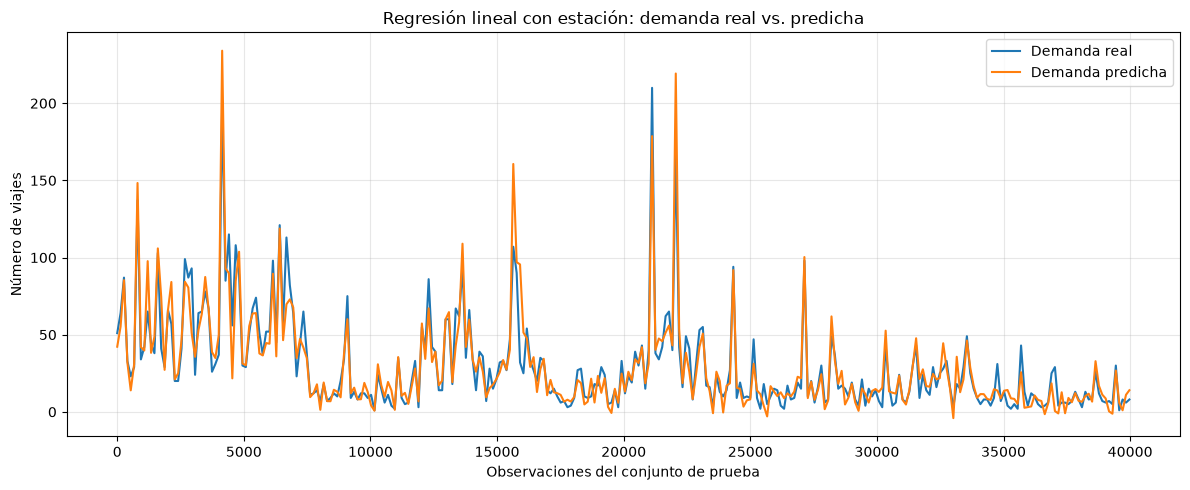

2026/10/17 09:53:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Pipeline_Regresion_Estacion_P1 at: http://127.0.0.1:5000/#/experiments/2/runs/27dc9273e1e345d9b4a48f52b06807d6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
MAE con estación: 6.687
RMSE con estación: 11.419
Gráfica guardada en: graficas_p1\regresion_estacion_real_vs_predicho.png
Pipeline, métricas y gráfica registrados en una nueva ejecución de MLflow.


In [85]:
# Paso 25. Entrenar y registrar el pipeline con estación
# Entrenar el pipeline exclusivamente con los datos de entrenamiento
pipeline_estacion_p1.fit(
    X_train_estacion_p1,
    y_train_estacion_p1
)

# Predecir sobre el conjunto de prueba
y_pred_estacion_p1 = pipeline_estacion_p1.predict(
    X_test_estacion_p1
)

# Calcular métricas
mae_estacion_p1 = mean_absolute_error(
    y_test_estacion_p1,
    y_pred_estacion_p1
)

rmse_estacion_p1 = np.sqrt(
    mean_squared_error(
        y_test_estacion_p1,
        y_pred_estacion_p1
    )
)

# Preparar los datos para la gráfica
y_real_grafica_estacion_p1 = np.asarray(
    y_test_estacion_p1
).reshape(-1)

y_pred_grafica_estacion_p1 = np.asarray(
    y_pred_estacion_p1
).reshape(-1)

# Mostrar como máximo 300 observaciones para facilitar la lectura
n_grafica_estacion_p1 = len(y_real_grafica_estacion_p1)

indices_grafica_estacion_p1 = np.unique(
    np.linspace(
        0,
        n_grafica_estacion_p1 - 1,
        min(300, n_grafica_estacion_p1),
        dtype=int
    )
)

# Crear gráfica de demanda real frente a demanda predicha
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    indices_grafica_estacion_p1,
    y_real_grafica_estacion_p1[indices_grafica_estacion_p1],
    label="Demanda real",
    linewidth=1.5
)

ax.plot(
    indices_grafica_estacion_p1,
    y_pred_grafica_estacion_p1[indices_grafica_estacion_p1],
    label="Demanda predicha",
    linewidth=1.5
)

ax.set_title(
    "Regresión lineal con estación: demanda real vs. predicha"
)
ax.set_xlabel("Observaciones del conjunto de prueba")
ax.set_ylabel("Número de viajes")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

# Guardar la gráfica localmente
carpeta_graficas_p1 = Path("graficas_p1")
carpeta_graficas_p1.mkdir(parents=True, exist_ok=True)

ruta_grafica_estacion_p1 = (
    carpeta_graficas_p1
    / "regresion_estacion_real_vs_predicho.png"
)

fig.savefig(
    ruta_grafica_estacion_p1,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Registrar en una ejecución de MLflow
with mlflow.start_run(
    run_name="Pipeline_Regresion_Estacion_P1"
):

    mlflow.log_param("modelo", "LinearRegression")
    mlflow.log_param(
        "preprocesamiento",
        "StandardScaler + OneHotEncoder"
    )
    mlflow.log_param(
        "registros_entrenamiento",
        len(X_train_estacion_p1)
    )
    mlflow.log_param(
        "registros_prueba",
        len(X_test_estacion_p1)
    )
    mlflow.log_param("fecha_inicio_prueba", "2026-07-01")
    mlflow.log_param("fecha_fin_prueba", "2026-09-30")
    mlflow.log_param("horizonte_dias", 1)

    mlflow.log_metric("MAE", mae_estacion_p1)
    mlflow.log_metric("RMSE", rmse_estacion_p1)

    mlflow.set_tag("tipo_experimento", "pipeline_con_estacion")
    mlflow.set_tag("git_commit", "888bc9d")
    

    # Registrar el modelo
    mlflow.sklearn.log_model(
        pipeline_estacion_p1,
        artifact_path="pipeline_regresion_estacion"
    )

    # Registrar la gráfica como artefacto
    mlflow.log_artifact(
        ruta_grafica_estacion_p1
       
    )


print(f"MAE con estación: {mae_estacion_p1:.3f}")
print(f"RMSE con estación: {rmse_estacion_p1:.3f}")
print(f"Gráfica guardada en: {ruta_grafica_estacion_p1}")
print("Pipeline, métricas y gráfica registrados en una nueva ejecución de MLflow.")


Mejora: representar el calendario de forma cíclica
Antes de cambiar de algoritmo, se propone mantener la regresión lineal y mejorar dos variables:
- Dia_semana: el domingo y el lunes son días consecutivos en el calendario, pero están lejos en su escala numérica actual.
- Mes: diciembre y enero son meses consecutivos, aunque sus valores numéricos son extremos opuestos.

Podemos representar ambas variables con funciones seno y coseno, que reflejan su naturaleza cíclica. 
Esto permite que el modelo aprenda patrones semanales sin imponer una relación lineal entre los números de los días.

In [86]:
def agregar_variables_ciclicas_p1(datos):
    datos = datos.copy()

    datos["Dia_semana_sin"] = np.sin(
        2 * np.pi * datos["Dia_semana"] / 7
    )
    datos["Dia_semana_cos"] = np.cos(
        2 * np.pi * datos["Dia_semana"] / 7
    )

    datos["Mes_sin"] = np.sin(
        2 * np.pi * (datos["Mes"] - 1) / 12
    )
    datos["Mes_cos"] = np.cos(
        2 * np.pi * (datos["Mes"] - 1) / 12
    )

    return datos


datos_entrenamiento_ciclico_p1 = agregar_variables_ciclicas_p1(
    datos_entrenamiento_modelo_p1
)

datos_prueba_ciclico_p1 = agregar_variables_ciclicas_p1(
    datos_prueba_modelo_p1
)

Preparar los datos y entrenar el modelo: Conservaremos las variables históricas y Fin_de_semana, pero sustituiremos Dia_semana y Mes por sus representaciones cíclicas.

In [87]:
variables_ciclicas_p1 = [
    "Viajes_dia_anterior",
    "Viajes_hace_7_dias",
    "Promedio_7_dias",
    "Fin_de_semana",
    "Dia_semana_sin",
    "Dia_semana_cos",
    "Mes_sin",
    "Mes_cos"
]

X_train_ciclico_p1 = datos_entrenamiento_ciclico_p1[
    variables_ciclicas_p1
]
y_train_ciclico_p1 = datos_entrenamiento_ciclico_p1[
    "Numero_viajes"
]

X_test_ciclico_p1 = datos_prueba_ciclico_p1[
    variables_ciclicas_p1
]
y_test_ciclico_p1 = datos_prueba_ciclico_p1[
    "Numero_viajes"
]

pipeline_ciclico_p1 = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

pipeline_ciclico_p1.fit(X_train_ciclico_p1, y_train_ciclico_p1)

y_pred_ciclico_p1 = pipeline_ciclico_p1.predict(X_test_ciclico_p1)

mae_ciclico_p1 = mean_absolute_error(
    y_test_ciclico_p1, y_pred_ciclico_p1
)
rmse_ciclico_p1 = np.sqrt(
    mean_squared_error(y_test_ciclico_p1, y_pred_ciclico_p1)
)

print(f"MAE del modelo cíclico: {mae_ciclico_p1:.3f}")
print(f"RMSE del modelo cíclico: {rmse_ciclico_p1:.3f}")

MAE del modelo cíclico: 6.646
RMSE del modelo cíclico: 11.366


Registrar el experimento en MLflow:

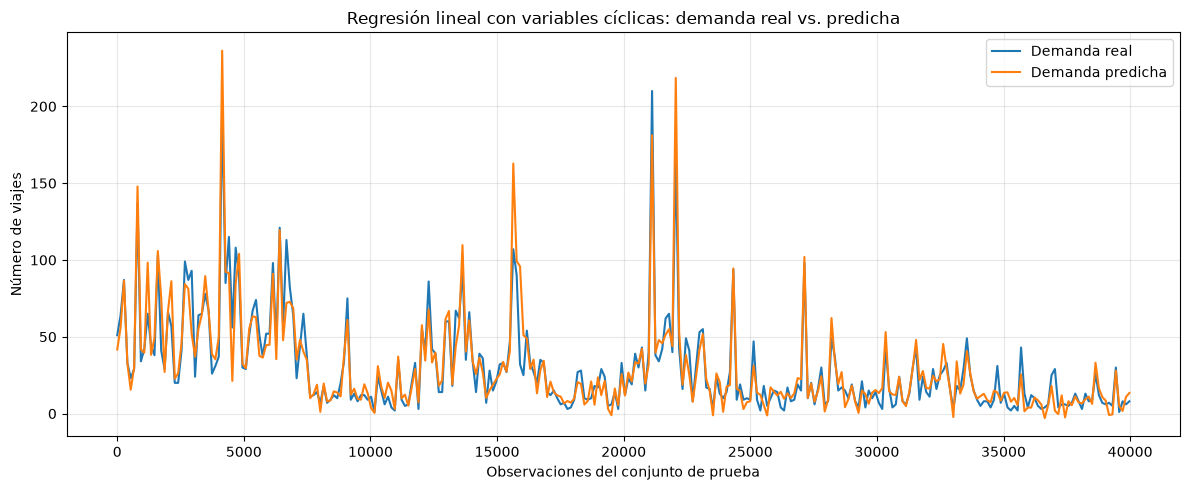

2026/10/17 09:53:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Pipeline_Regresion_Ciclica_P1 at: http://127.0.0.1:5000/#/experiments/2/runs/ec0a3d0e83ed4e58ad77aff4b02eadfd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
MAE cíclico: 6.646
RMSE cíclico: 11.366
Gráfica guardada en: graficas_p1\regresion_ciclica_real_vs_predicho.png
Modelo, métricas y gráfica registrados en una nueva ejecución de MLflow.


In [88]:
# Registrar el pipeline de regresión cíclica con gráfica
# Preparar los valores reales y predichos
y_real_grafica_ciclico_p1 = np.asarray(
    y_test_p1
).reshape(-1)

y_pred_grafica_ciclico_p1 = np.asarray(
    y_pred_ciclico_p1
).reshape(-1)

# Mostrar como máximo 300 observaciones para facilitar la lectura
n_grafica_ciclico_p1 = len(y_real_grafica_ciclico_p1)

indices_grafica_ciclico_p1 = np.unique(
    np.linspace(
        0,
        n_grafica_ciclico_p1 - 1,
        min(300, n_grafica_ciclico_p1),
        dtype=int
    )
)

# Crear gráfica de demanda real frente a demanda predicha
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    indices_grafica_ciclico_p1,
    y_real_grafica_ciclico_p1[indices_grafica_ciclico_p1],
    label="Demanda real",
    linewidth=1.5
)

ax.plot(
    indices_grafica_ciclico_p1,
    y_pred_grafica_ciclico_p1[indices_grafica_ciclico_p1],
    label="Demanda predicha",
    linewidth=1.5
)

ax.set_title(
    "Regresión lineal con variables cíclicas: demanda real vs. predicha"
)
ax.set_xlabel("Observaciones del conjunto de prueba")
ax.set_ylabel("Número de viajes")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

# Guardar la gráfica localmente
carpeta_graficas_p1 = Path("graficas_p1")
carpeta_graficas_p1.mkdir(parents=True, exist_ok=True)

ruta_grafica_ciclico_p1 = (
    carpeta_graficas_p1
    / "regresion_ciclica_real_vs_predicho.png"
)

fig.savefig(
    ruta_grafica_ciclico_p1,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Registrar en una ejecución de MLflow
with mlflow.start_run(
    run_name="Pipeline_Regresion_Ciclica_P1"
):

    mlflow.log_params({
        "modelo": "LinearRegression",
        "preprocesamiento": "StandardScaler",
        "horizonte_dias": 1,
        "fecha_inicio_prueba": "2026-07-01",
        "fecha_fin_prueba": "2026-09-30",
        "registros_entrenamiento": len(X_train_p1),
        "registros_prueba": len(X_test_p1)
        
    })

    mlflow.log_metrics({
        "MAE": mae_ciclico_p1,
        "RMSE": rmse_ciclico_p1
    })

    mlflow.set_tag("tipo_experimento", "pipeline_regresion_ciclica")
    mlflow.set_tag("git_commit", "888bc9d")

    # Registrar el modelo
    mlflow.sklearn.log_model(
        pipeline_ciclico_p1,
        artifact_path="pipeline_regresion_ciclica"
    )

    # Registrar la gráfica como artefacto
    mlflow.log_artifact(
        ruta_grafica_ciclico_p1
    )

    

print(f"MAE cíclico: {mae_ciclico_p1:.3f}")
print(f"RMSE cíclico: {rmse_ciclico_p1:.3f}")
print(f"Gráfica guardada en: {ruta_grafica_ciclico_p1}")
print("Modelo, métricas y gráfica registrados en una nueva ejecución de MLflow.")


Preparar la evaluación recursiva: Para evaluar pronósticos de siete días con orígenes móviles diarios. En cada origen, el modelo conocerá la demanda real hasta esa fecha; para los días siguientes utilizará sus propias predicciones para construir las variables históricas. Así evitamos la fuga de información durante cada pronóstico semanal.

In [89]:
matriz_demanda_p1 = (
    demanda_diaria_completa_p1
    .pivot(
        index="Origen_Id",
        columns="Fecha",
        values="Numero_viajes"
    )
    .sort_index(axis=1)
)

print("Estaciones disponibles:", matriz_demanda_p1.shape[0])
print("Fechas disponibles:", matriz_demanda_p1.shape[1])

Estaciones disponibles: 472
Fechas disponibles: 4322


Generar los pronósticos recursivos: Este bloque genera hasta siete predicciones por estación y por fecha de origen. Para evaluar los siete días completos, el último origen será el 23 de septiembre de 2026.

In [90]:
origenes_pronostico_p1 = pd.date_range(
    start="2026-06-30",
    end="2026-09-23",
    freq="D"
)

resultados_pronostico_7d_p1 = []

for fecha_origen in origenes_pronostico_p1:

    # Últimos siete días reales disponibles al iniciar el pronóstico
    fechas_historial = pd.date_range(
        end=fecha_origen,
        periods=7,
        freq="D"
    )

    historial_origen = (
        matriz_demanda_p1
        .reindex(columns=fechas_historial)
        .dropna(axis=0, how="any")
    )

    # Solo estaciones con siete días consecutivos de historial conocido
    historiales_estaciones = {
        estacion: historial_origen.loc[estacion].to_numpy(
            dtype=float
        ).tolist()
        for estacion in historial_origen.index
    }

    # Predecir un día a la vez, utilizando predicciones anteriores
    for horizonte in range(1, 8):

        fecha_objetivo = (
            fecha_origen + pd.Timedelta(days=horizonte)
        )
        estaciones_validas = list(historiales_estaciones.keys())
        if not estaciones_validas:
            break
        filas_variables = []
        for estacion in estaciones_validas:
            historial = historiales_estaciones[estacion][-7:]
            filas_variables.append({
                "Viajes_dia_anterior": historial[-1],
                "Viajes_hace_7_dias": historial[0],
                "Promedio_7_dias": np.mean(historial),
                "Fin_de_semana": int(fecha_objetivo.dayofweek >= 5),
                "Dia_semana_sin": np.sin(
                    2 * np.pi * fecha_objetivo.dayofweek / 7
                ),
                "Dia_semana_cos": np.cos(
                    2 * np.pi * fecha_objetivo.dayofweek / 7
                ),
                "Mes_sin": np.sin(
                    2 * np.pi * (fecha_objetivo.month - 1) / 12
                ),
                "Mes_cos": np.cos(
                    2 * np.pi * (fecha_objetivo.month - 1) / 12
                )
            })

        X_futuro_p1 = pd.DataFrame(
            filas_variables,
            columns=variables_ciclicas_p1
        )

        predicciones = pipeline_ciclico_p1.predict(X_futuro_p1)

        # Consultar la demanda real solo para evaluar, nunca para
        # construir las predicciones dentro del horizonte.
        valores_reales = (
            matriz_demanda_p1
            .reindex(
                index=estaciones_validas,
                columns=[fecha_objetivo]
            )[fecha_objetivo]
        )

        for i, estacion in enumerate(estaciones_validas):

            resultados_pronostico_7d_p1.append({
                "Fecha_origen": fecha_origen,
                "Fecha_pronostico": fecha_objetivo,
                "Horizonte_dias": horizonte,
                "Origen_Id": estacion,
                "Numero_viajes_real": valores_reales.loc[estacion],
                "Numero_viajes_predicho": predicciones[i]
            })

            # Actualizar el historial con la predicción, no con el dato real
            historiales_estaciones[estacion].append(
                float(predicciones[i])
            )
            historiales_estaciones[estacion] = (
                historiales_estaciones[estacion][-7:]
            )

pronosticos_7d_p1 = pd.DataFrame(
    resultados_pronostico_7d_p1
)

print("Total de pronósticos generados:", len(pronosticos_7d_p1))
print(
    "Estaciones evaluadas:",
    pronosticos_7d_p1["Origen_Id"].nunique()
)
print(
    "Fechas pronosticadas:",
    pronosticos_7d_p1["Fecha_pronostico"].min(),
    "a",
    pronosticos_7d_p1["Fecha_pronostico"].max()
)

Total de pronósticos generados: 261170
Estaciones evaluadas: 470
Fechas pronosticadas: 2026-07-01 00:00:00 a 2026-09-30 00:00:00


Evaluar los resultados: Calcularemos MAE y RMSE por horizonte. Es importante evaluarlos por separado porque el error puede crecer conforme nos alejamos de la fecha de origen.

In [91]:
pronosticos_evaluables_7d_p1 = pronosticos_7d_p1.dropna(
    subset=["Numero_viajes_real"]
).copy()

pronosticos_evaluables_7d_p1["Error_absoluto"] = (
    pronosticos_evaluables_7d_p1["Numero_viajes_real"]
    - pronosticos_evaluables_7d_p1["Numero_viajes_predicho"]
).abs()

metricas_horizonte_7d_p1 = (
    pronosticos_evaluables_7d_p1
    .groupby("Horizonte_dias")
    .apply(
        lambda grupo: pd.Series({
            "MAE": mean_absolute_error(
                grupo["Numero_viajes_real"],
                grupo["Numero_viajes_predicho"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                grupo["Numero_viajes_real"],
                grupo["Numero_viajes_predicho"]
            )),
            "Registros_evaluados": len(grupo)
        }),
        include_groups=False
    )
    .reset_index()
)

metricas_horizonte_7d_p1

,Horizonte_dias,MAE,RMSE,Registros_evaluados
0,1,6.635575,11.467017,37173.0
1,2,6.848564,11.710332,37146.0
2,3,6.898006,11.808131,37135.0
3,4,6.931295,11.879079,37127.0
4,5,6.933480,11.757346,37116.0
5,6,6.911010,11.731345,37109.0
6,7,6.998939,11.873337,37111.0


In [92]:
#Métrica global de todos los horizontes
mae_global_7d_p1 = mean_absolute_error(
    pronosticos_evaluables_7d_p1["Numero_viajes_real"],
    pronosticos_evaluables_7d_p1["Numero_viajes_predicho"]
)

rmse_global_7d_p1 = np.sqrt(mean_squared_error(
    pronosticos_evaluables_7d_p1["Numero_viajes_real"],
    pronosticos_evaluables_7d_p1["Numero_viajes_predicho"]
))

print(f"MAE global a siete días: {mae_global_7d_p1:.3f}")
print(f"RMSE global a siete días: {rmse_global_7d_p1:.3f}")

MAE global a siete días: 6.879
RMSE global a siete días: 11.747


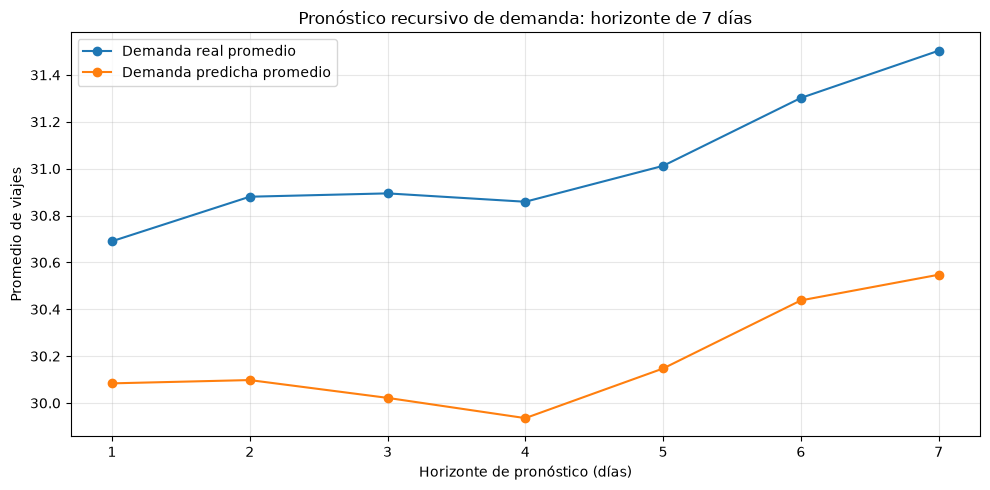

🏃 View run Pipeline_Regresion_Ciclica_7Dias_P1 at: http://127.0.0.1:5000/#/experiments/2/runs/b9cb855e768b430b87206b4acb259e7a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
MAE global a 7 días: 6.879
RMSE global a 7 días: 11.747
Gráfica guardada en: graficas_p1\regresion_ciclica_evaluacion_7_dias.png
Evaluación y gráfica registradas en una nueva ejecución de MLflow.


In [93]:
# Registrar evaluación recursiva de siete días con gráfica
# Resumir demanda real y predicha por horizonte
datos_grafica_7d_p1 = (
    pronosticos_evaluables_7d_p1
    .groupby("Horizonte_dias", as_index=False)
    .agg({
        "Numero_viajes_real": "mean",
        "Numero_viajes_predicho": "mean"
    })
    .sort_values("Horizonte_dias")
)

# Crear gráfica de demanda real promedio frente a predicha
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    datos_grafica_7d_p1["Horizonte_dias"],
    datos_grafica_7d_p1["Numero_viajes_real"],
    marker="o",
    label="Demanda real promedio"
)

ax.plot(
    datos_grafica_7d_p1["Horizonte_dias"],
    datos_grafica_7d_p1["Numero_viajes_predicho"],
    marker="o",
    label="Demanda predicha promedio"
)

ax.set_title("Pronóstico recursivo de demanda: horizonte de 7 días")
ax.set_xlabel("Horizonte de pronóstico (días)")
ax.set_ylabel("Promedio de viajes")
ax.set_xticks(range(1, 8))
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

# Guardar la gráfica localmente
carpeta_graficas_p1 = Path("graficas_p1")
carpeta_graficas_p1.mkdir(parents=True, exist_ok=True)

ruta_grafica_7d_p1 = (
    carpeta_graficas_p1
    / "regresion_ciclica_evaluacion_7_dias.png"
)

fig.savefig(
    ruta_grafica_7d_p1,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Registrar en una NUEVA ejecución de MLflow
with mlflow.start_run(
    run_name="Pipeline_Regresion_Ciclica_7Dias_P1"
):

    mlflow.log_params({
        "modelo": "Regresion_lineal_con_variables_ciclicas",
        "horizonte_dias": 7,
        "fecha_inicio_prueba": "2026-07-01",
        "fecha_fin_prueba": "2026-09-30",
        "tipo_evaluacion": "recursiva"
    })

    mlflow.log_metrics({
        "MAE": float(mae_global_7d_p1),
        "RMSE": float(rmse_global_7d_p1)
    })

    mlflow.set_tag("tipo_experimento", "evaluacion_recursiva_7_dias")
    mlflow.set_tag("git_commit", "888bc9d")

    # Registrar la gráfica como artefacto
    mlflow.log_artifact(
        ruta_grafica_7d_p1
    
    )
print(f"MAE global a 7 días: {mae_global_7d_p1:.3f}")
print(f"RMSE global a 7 días: {rmse_global_7d_p1:.3f}")
print(f"Gráfica guardada en: {ruta_grafica_7d_p1}")
print("Evaluación y gráfica registradas en una nueva ejecución de MLflow.")


In [94]:
# Copiar los resultados del pronóstico recursivo
comparacion_7d_p1 = pronosticos_evaluables_7d_p1.copy()

# Baseline: mantener la demanda observada en la fecha de origen
comparacion_7d_p1["Prediccion_baseline"] = [
    matriz_demanda_p1.loc[estacion, fecha]
    for estacion, fecha in zip(
        comparacion_7d_p1["Origen_Id"],
        comparacion_7d_p1["Fecha_origen"]
    )
]

# Calcular métricas para ambos métodos en cada horizonte
filas_metricas_7d_p1 = []

for horizonte, grupo in comparacion_7d_p1.groupby("Horizonte_dias"):

    reales = grupo["Numero_viajes_real"]
    pred_modelo = grupo["Numero_viajes_predicho"]
    pred_baseline = grupo["Prediccion_baseline"]

    filas_metricas_7d_p1.append({
        "Horizonte_dias": int(horizonte),
        "MAE_modelo": mean_absolute_error(reales, pred_modelo),
        "RMSE_modelo": np.sqrt(
            mean_squared_error(reales, pred_modelo)
        ),
        "MAE_baseline": mean_absolute_error(reales, pred_baseline),
        "RMSE_baseline": np.sqrt(
            mean_squared_error(reales, pred_baseline)
        ),
        "Registros": len(grupo)
    })

comparacion_metricas_7d_p1 = pd.DataFrame(filas_metricas_7d_p1)

comparacion_metricas_7d_p1.round(3)

,Horizonte_dias,MAE_modelo,RMSE_modelo,MAE_baseline,RMSE_baseline,Registros
0,1,6.636,11.467,9.108,15.930,37173
1,2,6.849,11.710,10.814,18.355,37146
2,3,6.898,11.808,10.768,18.204,37135
3,4,6.931,11.879,10.873,18.204,37127
4,5,6.933,11.757,11.217,18.990,37116
5,6,6.911,11.731,9.632,16.619,37109
6,7,6.999,11.873,7.382,13.231,37111


In [95]:
(pronosticos_7d_p1["Numero_viajes_predicho"] < 0).sum()

np.int64(6987)

## Resultados y limitaciones

### Resultados

En la comparación de modelos para la pregunta P1, el modelo de regresión lineal con variables temporales cíclicas obtuvo el mejor desempeño entre los modelos evaluados para el pronóstico de un día. Sus resultados fueron un MAE de 6.646 y un RMSE de 11.366, ligeramente mejores que los de la regresión lineal sin variables cíclicas y la regresión que incorpora el identificador de la estación. El modelo baseline, que utiliza la demanda del día anterior como predicción, presentó errores considerablemente mayores.

Para evaluar el pronóstico de los siguientes siete días, se utilizó una estrategia recursiva: las predicciones de cada día se incorporaron al historial para calcular los pronósticos de los días posteriores, sin utilizar sus valores reales futuros como entradas. En esta evaluación, el modelo obtuvo un MAE global de 6.879 y un RMSE de 11.747. Además, superó al baseline evaluado por horizonte en los siete días. El MAE del modelo se mantuvo relativamente estable, entre 6.636 y 6.999 viajes, mientras que la diferencia respecto al baseline fue menor en el séptimo día.

Estos resultados indican que las variables de historial de demanda y calendario aportan información útil para pronosticar los viajes por estación. Por ello, la regresión lineal con variables cíclicas puede considerarse una alternativa inicial para apoyar la planeación de la disponibilidad de bicicletas, aunque su desempeño debe validarse bajo condiciones operativas reales.

### Limitaciones

La evaluación se realizó con datos históricos y un periodo de prueba comprendido entre julio y septiembre de 2026. Aunque se respetó el orden temporal y el pronóstico recursivo utilizó sus propias predicciones para avanzar dentro de cada horizonte, la evaluación corresponde a múltiples fechas de origen. Por lo tanto, no representa exactamente el escenario de emitir una única predicción de siete días a partir de una fecha actual y utilizarla sin actualización durante toda la semana.

Otra limitación es la presencia de fechas sin registros para algunas estaciones. Estos valores se conservaron como faltantes en lugar de asumir que representan cero viajes, por lo que el conjunto evaluable no incluye todas las combinaciones posibles de estación y fecha. Asimismo, algunas estaciones presentes en el periodo de prueba no tenían suficiente historial en el entrenamiento, lo que limita la generalización de los resultados a estaciones nuevas o con datos incompletos.

El modelo utiliza principalmente la demanda reciente y variables de calendario. No considera factores externos como el clima, los días festivos, los eventos, las fallas de estaciones ni la disponibilidad efectiva de bicicletas. Además, las métricas globales pueden ocultar diferencias importantes entre estaciones con niveles de demanda distintos. La regresión lineal también puede generar predicciones negativas, por lo que debe revisarse este comportamiento antes de utilizar sus resultados en una operación real.

Como trabajo futuro, sería conveniente evaluar el error por estación y por nivel de demanda, comparar diferentes ventanas temporales y añadir variables externas relevantes. También sería útil probar el modelo en una evaluación de origen fijo de siete días y establecer un mecanismo de actualización periódica. De esta forma, se podría determinar con mayor precisión si las predicciones son suficientemente confiables para apoyar decisiones de distribución y disponibilidad de bicicletas.